# Prédiction du churn client — Telco

**Objectif** : comprendre pourquoi des clients quittent un opérateur télécom,
puis prédire lesquels risquent de partir.

**Données** : [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
(Kaggle) — 7 043 clients, 21 colonnes.

Ce notebook couvre l'exploration. La modélisation est dans `02_modelisation.ipynb`.

## 1. Imports et chargement

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Nettoyage

`TotalCharges` est un montant, mais elle est lue comme du texte (`object`) :
certaines valeurs ne sont pas des nombres.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum()

np.int64(11)

11 valeurs vides, toutes avec `tenure = 0` : ce sont de nouveaux clients jamais facturés. On les remplace par 0.

In [5]:
mask = pd.to_numeric(df["TotalCharges"], errors="coerce").isna()
df.loc[mask, ["tenure", "MonthlyCharges", "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,
753,0,20.25,
936,0,80.85,
1082,0,25.75,
1340,0,56.05,
3331,0,19.85,
3826,0,25.35,
4380,0,20.00,
5218,0,19.70,
6670,0,73.35,


In [6]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["TotalCharges"].dtype

dtype('float64')

In [7]:
# customerID est un identifiant : il ne prédit rien
df = df.drop(columns=["customerID"])
df.shape

(7043, 20)

## 3. Analyse de la cible

On passe `Churn` en 0/1 (1 = le client est parti).

In [8]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df["Churn"].mean()

np.float64(0.2653698707936959)

**26,5 % de churn** : la cible est déséquilibrée. Un modèle qui prédit toujours « reste » aurait déjà 73,5 % d'accuracy.

## 4. Exploration des variables

### Contrat et ancienneté

In [9]:
df.groupby("Contract")["Churn"].mean()

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64

Environ 43% des clients avec un abo. mensuel partent (contre 11% sur 1 an et 3% sur 2 ans). Piste : inciter aux contrats longs

In [10]:
df.groupby("Churn")["tenure"].mean()

Churn
0    37.569965
1    17.979133
Name: tenure, dtype: float64

Les clients qui partent ont en moyenne 18 mois d'ancienneté, contre 38 mois pour ceux qui restent. Les départs se concentrent sur les clients récents.

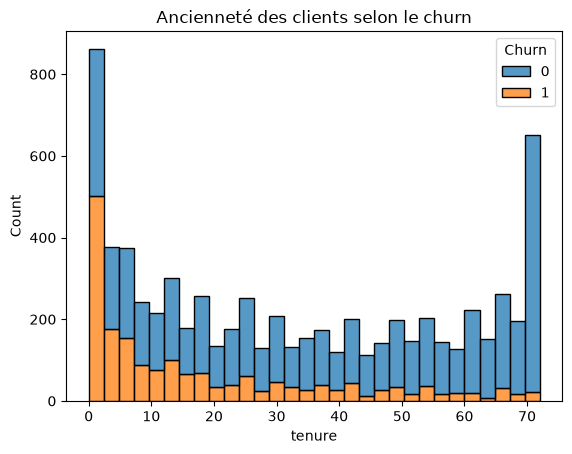

In [11]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack")
plt.title("Ancienneté des clients selon le churn")
plt.show()

**Contrat court + client récent = risque élevé**

### Facture et type d'internet

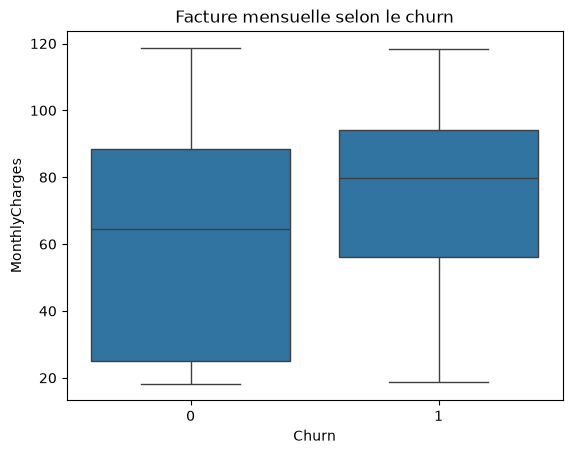

In [12]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Facture mensuelle selon le churn")
plt.show()

Les clients qui partent ont généralement des factures plus élevées. Mais tous les clients chers ne partent pas, les deux boîtes se chevauchent beaucoup.

In [13]:
df.groupby("InternetService")["Churn"].mean()

InternetService
DSL            0.189591
Fiber optic    0.418928
No             0.074050
Name: Churn, dtype: float64

Valeurs en accord avec le graph. précédent, la fibre étant le service le plus cher. Hypothèse possible : clients mécontents du rapport qualité/prix.

### Autres variables

Taux de churn pour chaque modalité de toutes les variables texte.

In [14]:
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    print(df.groupby(col)["Churn"].mean().round(2), "\n")

gender
Female    0.27
Male      0.26
Name: Churn, dtype: float64 

Partner
No     0.33
Yes    0.20
Name: Churn, dtype: float64 

Dependents
No     0.31
Yes    0.15
Name: Churn, dtype: float64 

PhoneService
No     0.25
Yes    0.27
Name: Churn, dtype: float64 

MultipleLines
No                  0.25
No phone service    0.25
Yes                 0.29
Name: Churn, dtype: float64 

InternetService
DSL            0.19
Fiber optic    0.42
No             0.07
Name: Churn, dtype: float64 

OnlineSecurity
No                     0.42
No internet service    0.07
Yes                    0.15
Name: Churn, dtype: float64 

OnlineBackup
No                     0.40
No internet service    0.07
Yes                    0.22
Name: Churn, dtype: float64 

DeviceProtection
No                     0.39
No internet service    0.07
Yes                    0.23
Name: Churn, dtype: float64 

TechSupport
No                     0.42
No internet service    0.07
Yes                    0.15
Name: Churn, dtype: float64 

S

C:\Users\yacin\AppData\Local\Temp\ipykernel_35692\2180955886.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


- OnlineSecurity / TechSupport : environ 42 % de churn sans l’option, contre 15 % avec.
- OnlineBackup : environ 40 % sans, 22 % avec.
- Dependents : environ 31 % sans personne à charge, 15 % avec.
- PaymentMethod :  environ 45% de churn par "Electronic check" contre 15, 17 et 19% pour les autres moyens de paiement.

## 5. Conclusion

Les clients qui partent sont surtout :
- récents (moins de 18 mois en moyenne), en contrat mensuel
- abonnés à la fibre, avec une facture plus élevée
- sans options de sécurité, de sauvegarde ou de support technique
- sans personne à charge, et payant par chèque électronique

Piste : cibler les nouveaux clients au mois pour leur proposer
un contrat plus long ou des options de support.